In [5]:
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
import astropy.units as u
from scipy import stats

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors


from astropy.nddata import CCDData
from ccdproc import wcs_project



In [6]:
# defining imdisplay and imdisplay2 from the lab 

def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax



def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs



In [8]:
# specifying data directory
datadir = '/Users/bryanwilliams/Desktop/ASTR596/Data/Capstone/'
os.chdir(datadir)


0.00028405884513631446 10.000004768371582


Text(0.5, 1.0, 'NGC1087-image-r.fits.fz')

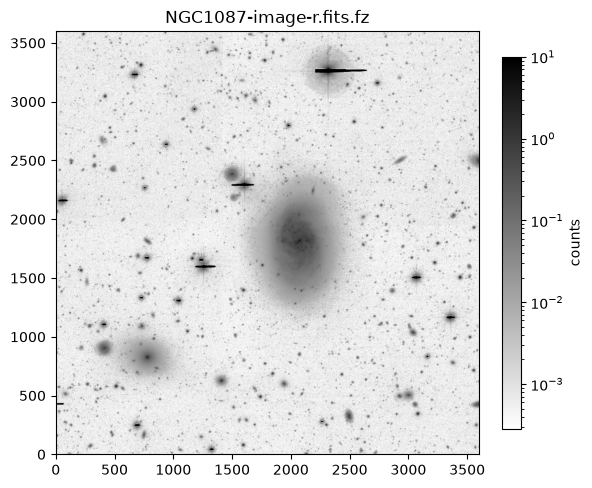

In [9]:
imname = 'NGC1087-image-r.fits.fz'
#fig,ax = plt.subplots(figsize=(6,6))
data,header = fits.getdata(imname, header=True)
fig,ax = imdisplay(data,v1perc=45,v2perc=99.9,logscale=True)

plt.title(imname)


# Measure background so we can subtract it from the image so that when we measure flux from spiral galaxy all flux we measure comes from source and not other sources. 

In [10]:
# to measure the background

def background_meas(imname,data,header,fig,ax,corners,bkg_size=5):
    #need to find ways to select regions of pixels in image
    fig,ax = imdisplay(data,v1perc=45,v2perc=99,logscale=True)

    plt.title(imname)

    #print out the x and y-dimension of the image using the header keywords
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    #the length of each background box size
    #bkg_size = 200

    #make an array whose elements are the different data sections.
    reg = np.array([])


    #specify the different regions.  Each will be appended to the reg array.  the reg array is therefore 3 dimensional.  
    #the first dimension is for each region.  Each of those dimensions contains a 2D array that holds the image section.
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])    #lower left corner
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])    #upper left corner
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    #upper right corner
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1])   #lower right corner

    #print the median and mode of all the pixels. 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)

    #Overlay rectangles with the background region indicated
    rectlist = []
    #loop through all images 
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed

In [11]:
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}


In [12]:
#a routine to plot the images with the background measurement corners shown in red
def bkgregplot(data,header,imname, bkgdim, fig, ax):
    #define lower-left corners of each region
    corners = []
    corners.append([0,0])
    corners.append([0,header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim, header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim,0])

    #run the background_meas code to measure the background and plot the background regions
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed

0.00028405884513631446 0.18426934093236919
image xdim =  3600 ; image ydim =  3600
mode =  0.0
median =  0.0002116672694683075


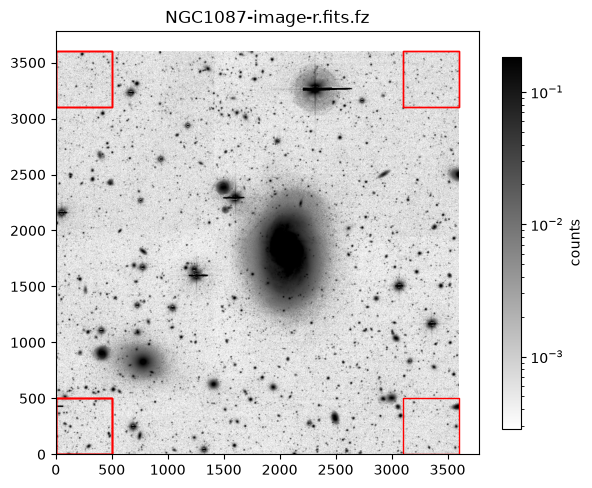

In [13]:
galname = 'NGC1087'
imname[galname] = 'NGC1087-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 500

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

0.0004112009206437505 0.1532127293944358
image xdim =  3600 ; image ydim =  3600
mode =  0.0
median =  0.00015075498959049582


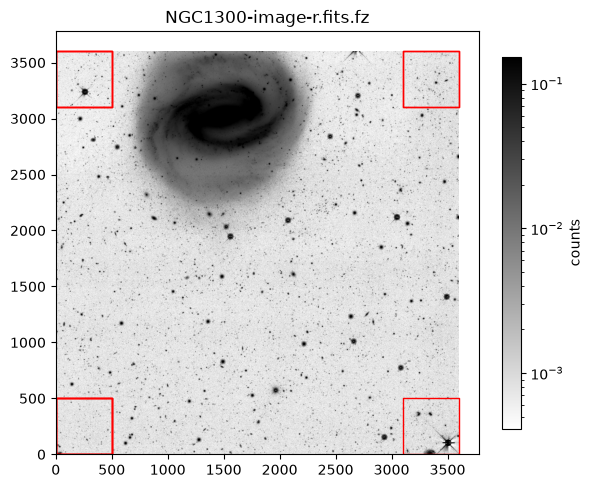

In [14]:
galname = 'NGC1300'
imname[galname] = 'NGC1300-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 500

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

0.00034531305427663015 0.26477262204629354
image xdim =  3600 ; image ydim =  3600
mode =  -0.0003913726832251996
median =  0.00014180413563735783


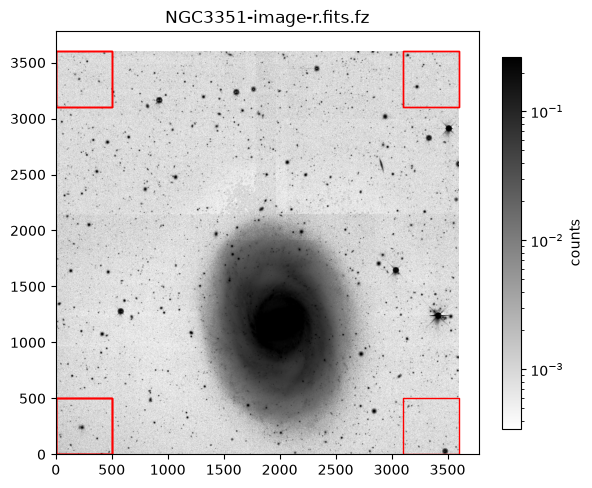

In [15]:
galname = 'NGC3351'
imname[galname] = 'NGC3351-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 500

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

0.0006081067374907434 0.3617388790845867
image xdim =  3600 ; image ydim =  3600
mode =  -0.005266719032078981
median =  0.0002646086213644594


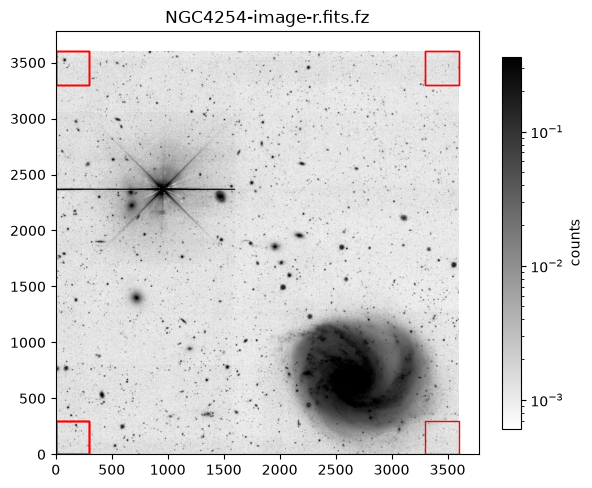

In [16]:
galname = 'NGC4254'
imname[galname] = 'NGC4254-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 300

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

0.00018370522157056248 0.12360173180699321
image xdim =  3600 ; image ydim =  3600
mode =  0.0
median =  0.00027342879911884665


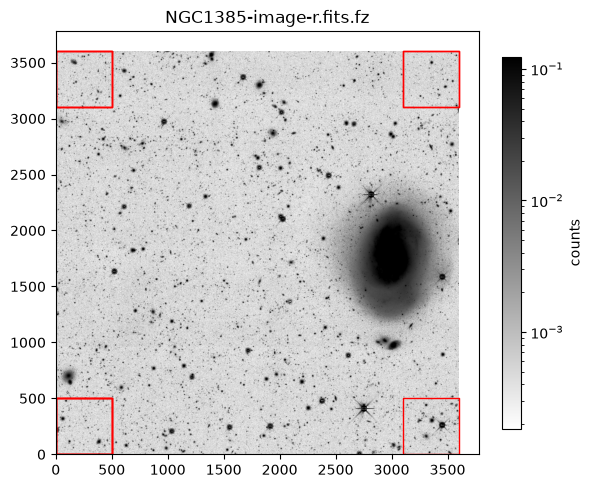

In [17]:
galname = 'NGC1385'
imname[galname] = 'NGC1385-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#the size of the background squares
bkgdim[galname]= 500

#plot image with background regions
bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

# Code to subtract the background we measured from image. 

In [18]:
#initializse dictionary that will hold background subtracted images
data_bsub = {}
imname_bsub = {}

7.239157566800696e-05 9.999793101102114


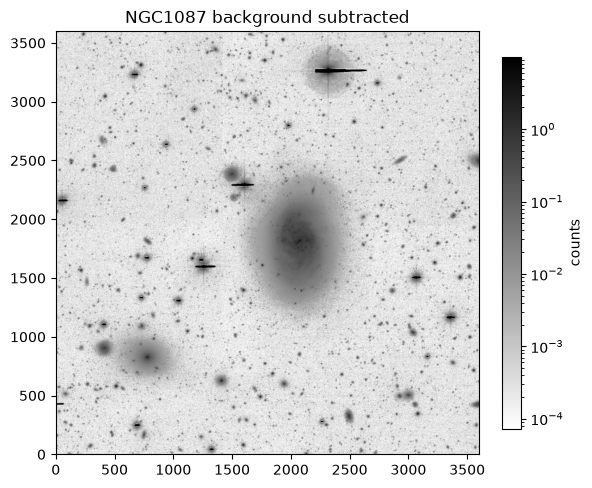

In [19]:
galname = 'NGC1087'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=45,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("fits","bsub.fits")

# save the background_subtracted image to a file
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

0.00026044593105325467 0.5683696815357742


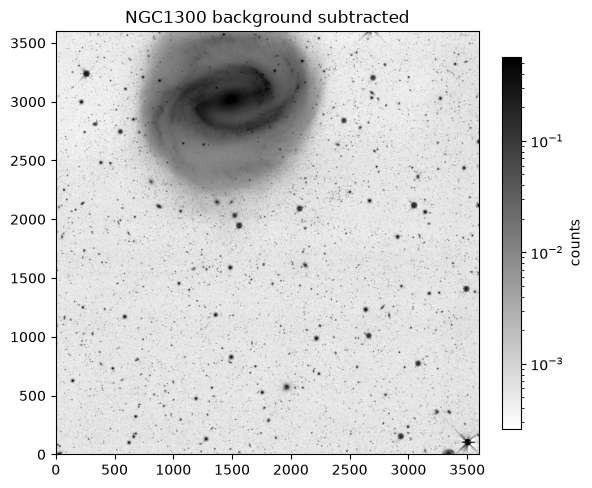

In [20]:
galname = 'NGC1300'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=45,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("fits","bsub.fits")

# save the background_subtracted image to a file
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

0.00020350891863927232 1.59590178318979


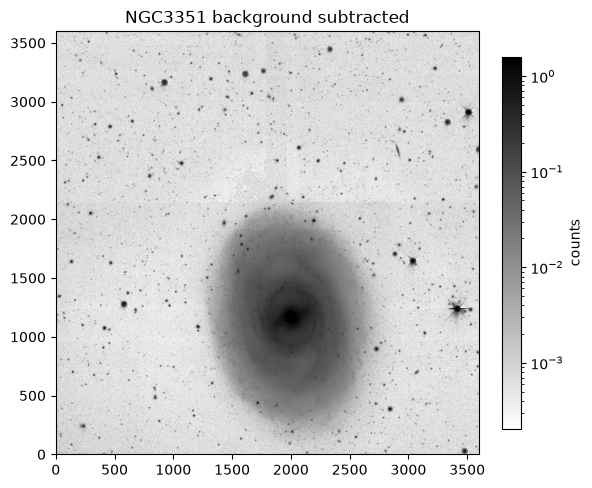

In [21]:
galname = 'NGC3351'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=45,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("fits","bsub.fits")

# save the background_subtracted image to a file
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

0.00034349811612628396 9.999736345052952


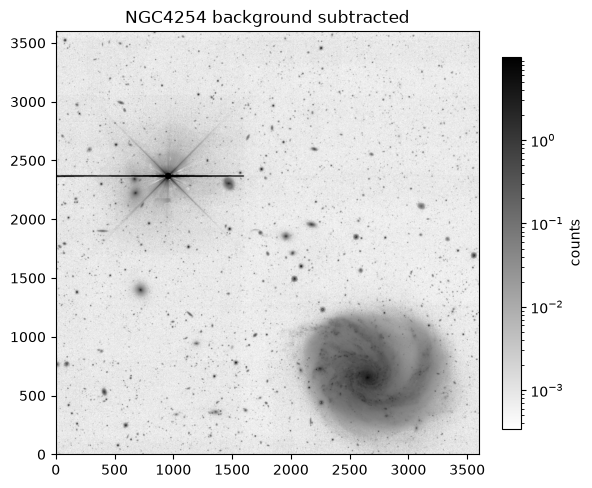

In [22]:
galname = 'NGC4254'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=45,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("fits","bsub.fits")

# save the background_subtracted image to a file
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

4.103312268853164e-05 1.1028318741309935


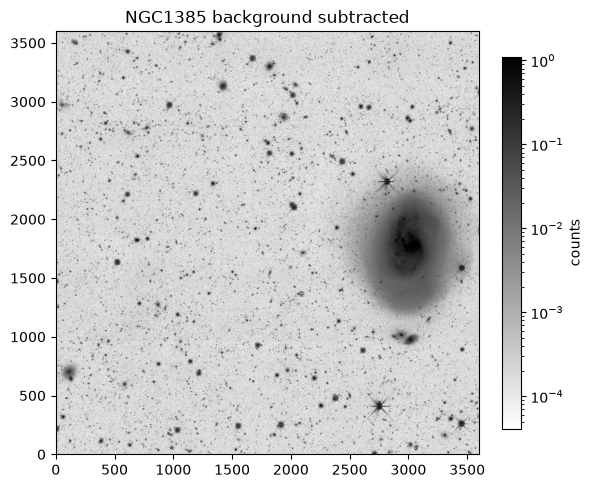

In [23]:
galname = 'NGC1385'

#background subtract the data
data_bsub[galname] = data[galname] - bkgmed[galname]

#display the background subtracted data
fig,ax =imdisplay(data_bsub[galname],v1perc=47,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname + ' background subtracted')

#make a new image name that replaces one string with another
imname_bsub[galname] = imname[galname].replace("fits","bsub.fits")

# save the background_subtracted image to a file
fits.writeto(imname_bsub[galname],data_bsub[galname],overwrite=True,header=header[galname])

# Make initial ellipses for Isophote fittings using DS9

In [24]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}

In [25]:
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC1087'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2071
initparams[galname]['ycen'] = 1816
#semi-major axis [pixels]
initparams[galname]['sma'] = 207
#semin-minor axis [pixels]
initparams[galname]['smina'] = 151
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 90.0

In [26]:
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC1300'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 1491
initparams[galname]['ycen'] = 3023
#semi-major axis [pixels]
initparams[galname]['sma'] = 474
#semin-minor axis [pixels]
initparams[galname]['smina'] = 309
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 20.0

In [27]:
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC3351'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2002
initparams[galname]['ycen'] = 1166
#semi-major axis [pixels]
initparams[galname]['sma'] = 550
#semin-minor axis [pixels]
initparams[galname]['smina'] = 331
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 100.0

In [28]:
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC4254'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2729
initparams[galname]['ycen'] = 712
#semi-major axis [pixels]
initparams[galname]['sma'] = 500
#semin-minor axis [pixels]
initparams[galname]['smina'] = 407
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 0.0

In [29]:
#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC1385'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 3007
initparams[galname]['ycen'] = 1778
#semi-major axis [pixels]
initparams[galname]['sma'] = 299
#semin-minor axis [pixels]
initparams[galname]['smina'] = 196
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 90.0

In [31]:
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture

#define an empty dictionary that will contain the EllipseGeometry instance
geometry = {}

207 0.27053140096618356


7.239157566800696e-05 9.99983410909772


Text(0.5, 1.0, 'NGC1087')

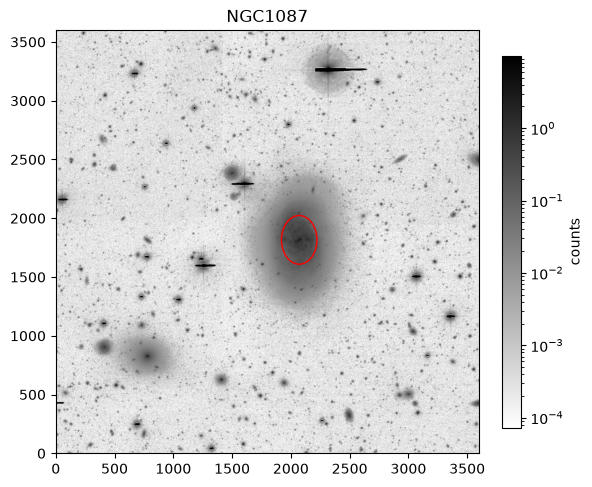

In [32]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC1087'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=45,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

474 0.3481012658227848


0.00026044593105325467 9.999864503799472


Text(0.5, 1.0, 'NGC1300')

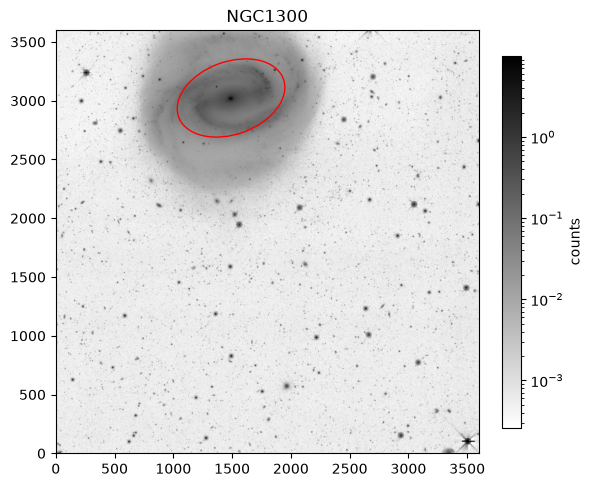

In [33]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC1300'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=45,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

550 0.3981818181818182


0.00020350891863927232 9.999490665039048


Text(0.5, 1.0, 'NGC3351')

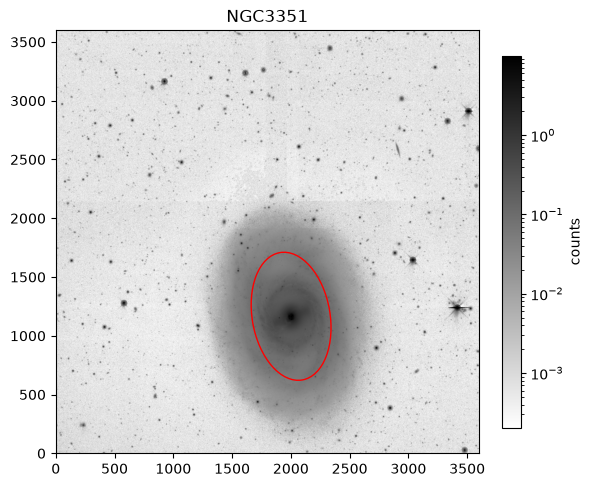

In [34]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC3351'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=45,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

500 0.18600000000000005


0.00034349811612628396 9.999783075094456


Text(0.5, 1.0, 'NGC4254')

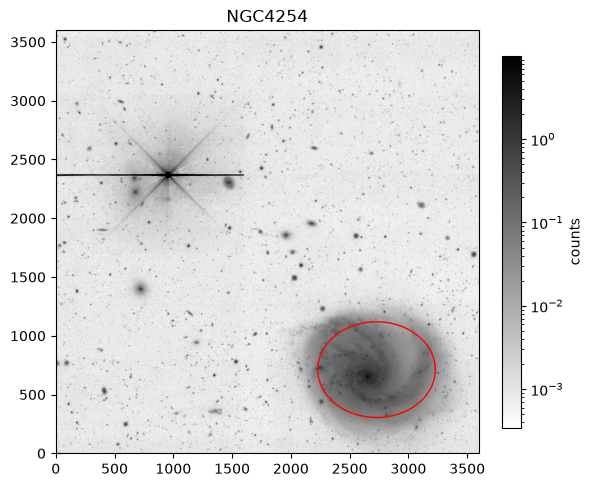

In [35]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC4254'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=45,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

299 0.34448160535117056


4.103312268853164e-05 9.999750413058791


Text(0.5, 1.0, 'NGC1385')

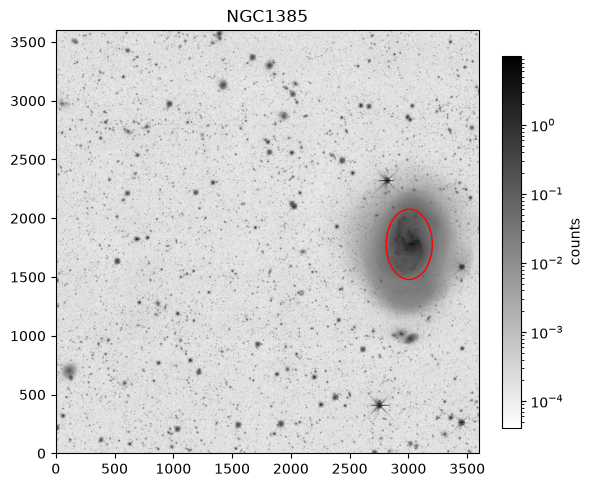

In [36]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC1385'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data_bsub[galname],v1perc=47,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

#


# 

In [37]:
def plotellipse(isolist):
    plt.figure(figsize=(8, 8))
    plt.subplots_adjust(hspace=0.35, wspace=0.35)

    #plot the semi-major axis vs. the ellipticity
    plt.subplot(2, 2, 1)
    plt.errorbar(isolist.sma, isolist.eps, yerr=isolist.ellip_err,
                 fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('Ellipticity')

    #plot the semi-major axis vs. the PA
    plt.subplot(2, 2, 2)
    plt.errorbar(isolist.sma, isolist.pa / np.pi * 180.0,
                 yerr=isolist.pa_err / np.pi * 180.0, fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('PA (deg)')

    #plot the semi-major axis vs. the x center of that ellipse
    plt.subplot(2, 2, 3)
    plt.errorbar(isolist.sma, isolist.x0, yerr=isolist.x0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('x0')

    #plot the semi-major axis vs. the y center of that ellipse
    plt.subplot(2, 2, 4)
    plt.errorbar(isolist.sma, isolist.y0, yerr=isolist.y0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('y0')

In [38]:
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list,vminperc=50,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
    
        #overplot apertures
        aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])
    
    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
    
        #overplot apertures
        aperiter.plot(ax=ax[1],color='blue')

    ax[0].set_title(galname + ' free ellipse parameters')
    ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav



In [39]:
from photutils.isophote import Ellipse

#initialize dictionary for ellipse fitting
ellipse = {}
isolist = {}
xcenav = {}
ycenav = {}
epsav = {}
paav = {}

In [40]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC1087'
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

v1 =  0.00, v2 = 10.00


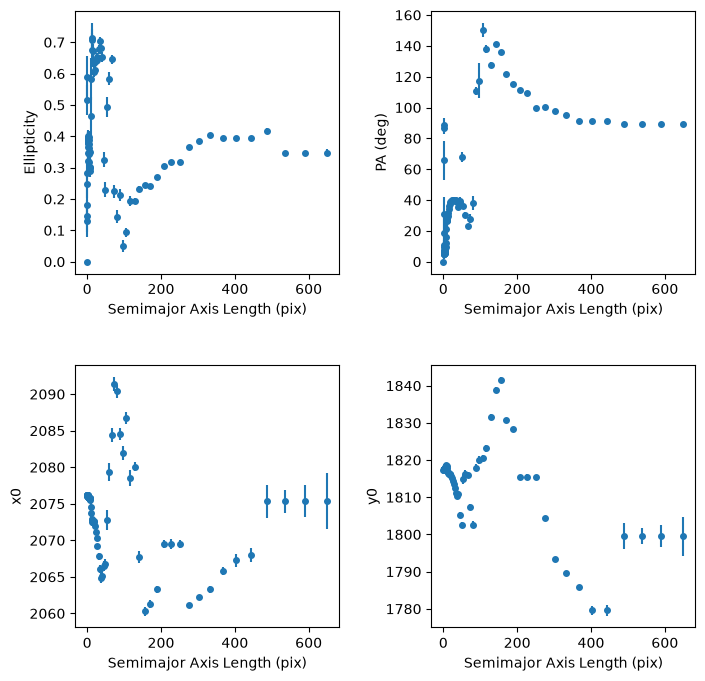

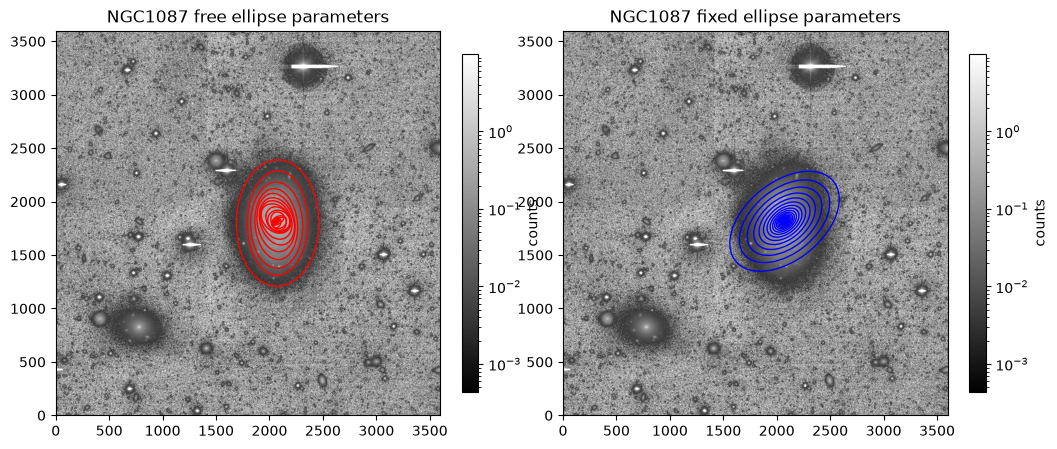

In [41]:
#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

In [42]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC1300' 
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

[0.         0.46330888 0.46490437 0.4612764  0.32908165 0.19530052
 0.04228715 0.02856289 0.02558509 0.02558509 0.01910117 0.01910117
 0.01248556 0.01780871 0.02944705 0.04380364 0.05495588 0.06733831
 0.06696547 0.06659529 0.06659529 0.07757988 0.08492117 0.08881115
 0.09636138 0.10882916 0.11571067 0.11753548 0.11282838 0.08713247
 0.01747339 0.01747339 0.00848328 0.03822121 0.09442016 0.1526906
 0.21226589 0.24076608 0.23500313 0.23198931 0.22774498 0.21322339
 0.19416223 0.19750838 0.2063484  0.36460445 0.31697016 0.29192645
 0.30181029 0.32703569 0.34005874 0.35637699 0.38132079 0.41111541
 0.42816049 0.44855004 0.46789012 0.48479448 0.50193132 0.52585619
 0.5513294  0.57691331 0.59056541 0.63844107 0.63844107 0.73797614
 0.75631604 0.76136175 0.78455231 0.76245409 0.74562058 0.6815283
 0.34810127 0.39244247 0.43778232 0.456481   0.456481   0.06842733
 0.06842733]
v1 =  0.00, v2 = 10.00


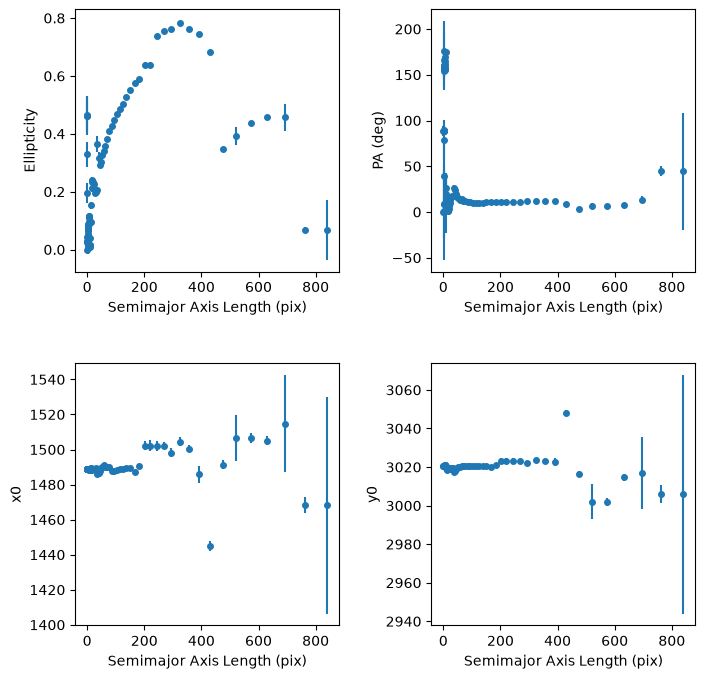

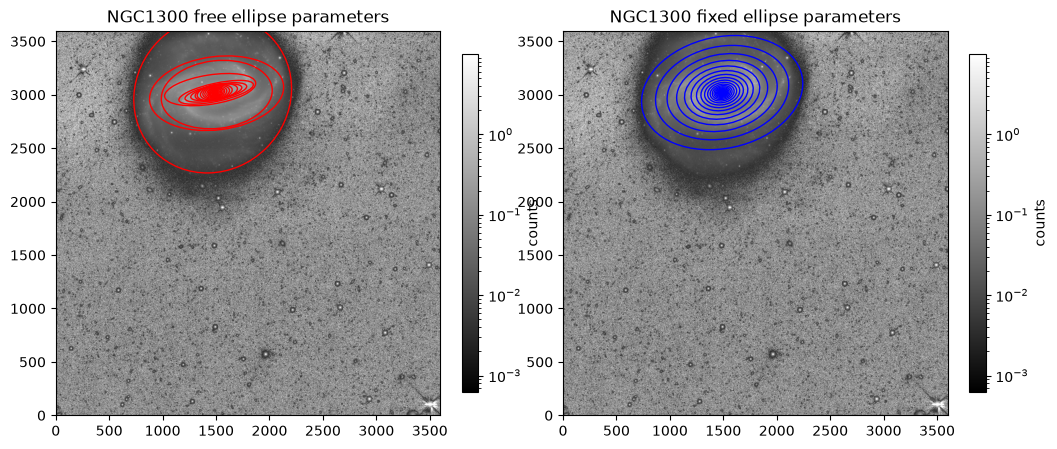

In [43]:
#this puts the output into a table containing every ellipse.   
#You can comment this first line out if you don't want it always to print out.
print(isolist[galname].eps)

#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

In [44]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC3351'
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

[0.         0.24600135 0.24600135 0.24600135 0.24600135 0.24600135
 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135
 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135
 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135
 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135
 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135 0.24600135
 0.24600135 0.24600135 0.24600135 0.5806872  0.12335445 0.12335445
 0.14507467 0.14182178 0.12958797 0.12837968 0.11611135 0.11180801
 0.08822339 0.08590763 0.09387589 0.09871862 0.10059075 0.00640406
 0.05157362 0.09356819 0.15555392 0.19563225 0.23530904 0.29447861
 0.33750902 0.36734431 0.36488725 0.41656931 0.4263181  0.39571553
 0.11669766 0.08886843 0.08886843 0.06742447 0.09189028 0.15769915
 0.16890501 0.21965104 0.24600135 0.27274949 0.29137161 0.31154595
 0.34043481 0.34043481 0.28287863 0.28287863 0.28287863 0.28287863
 0.28287863]
v1 =  0.00, v2 = 10.00


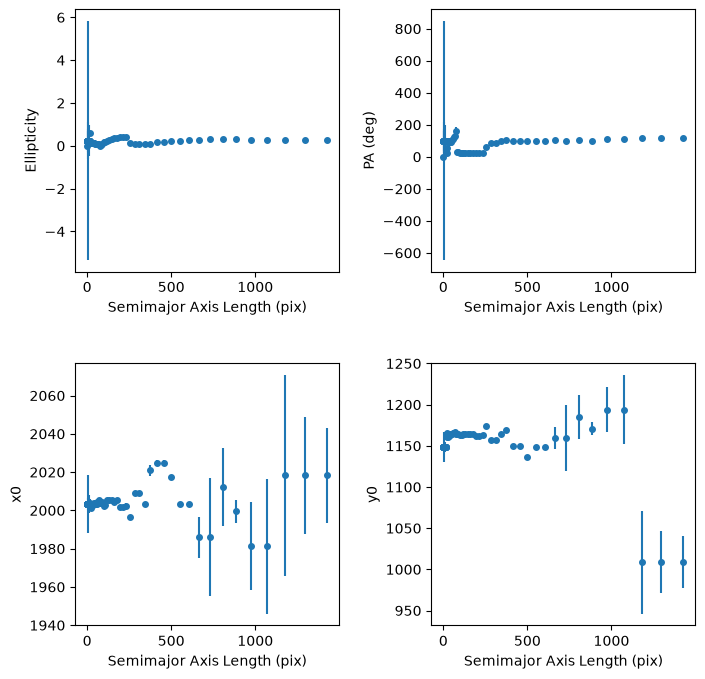

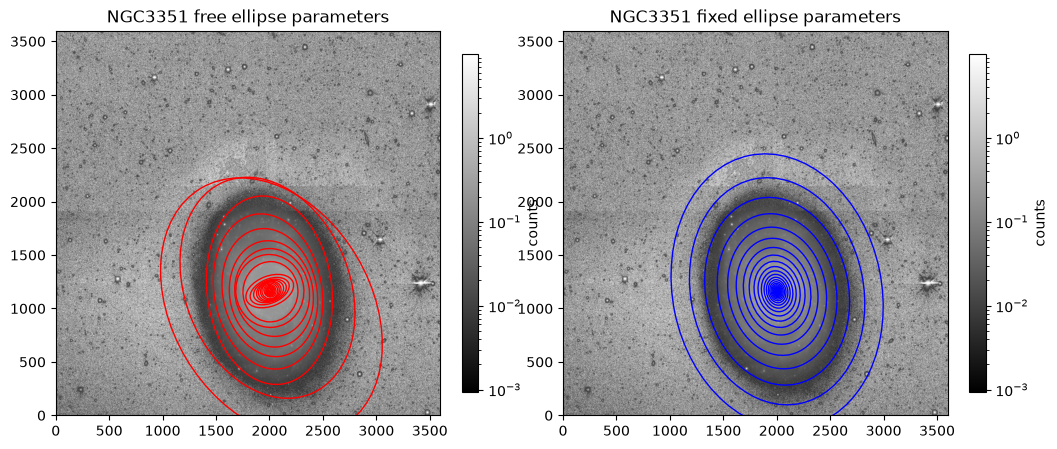

In [45]:
#this puts the output into a table containing every ellipse.   
#You can comment this first line out if you don't want it always to print out.
print(isolist[galname].eps)

#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

In [46]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC4254'
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

[0.         0.64829828 0.49260944 0.23760622 0.03987052 0.03056577
 0.03056577 0.02122958 0.01851785 0.02216764 0.02539397 0.02539397
 0.02812859 0.03190668 0.03068915 0.03004167 0.03596615 0.0261183
 0.0450294  0.05446752 0.05312222 0.06317533 0.06787108 0.0737401
 0.04771094 0.04771094 0.04771094 0.04771094 0.04771094 0.04771094
 0.10597636 0.16817409 0.2089387  0.22025232 0.21988309 0.226764
 0.2316615  0.2255269  0.23722641 0.23711263 0.20200209 0.24496325
 0.05304768 0.05304768 0.09828647 0.11335331 0.10293904 0.21615053
 0.19315546 0.22935108 0.26660144 0.31548753 0.38214486 0.25073488
 0.3730241  0.28720988 0.19548522 0.19005436 0.19005436 0.34593133
 0.30133197 0.00129003 0.00129003 0.08790392 0.1848857  0.140586
 0.06971339 0.27124363 0.19889555 0.19889555 0.19889555 0.28646815
 0.28682537 0.28682537 0.28682537 0.28682537 0.14166319 0.14166319
 0.14166319]
v1 =  0.00, v2 = 10.00


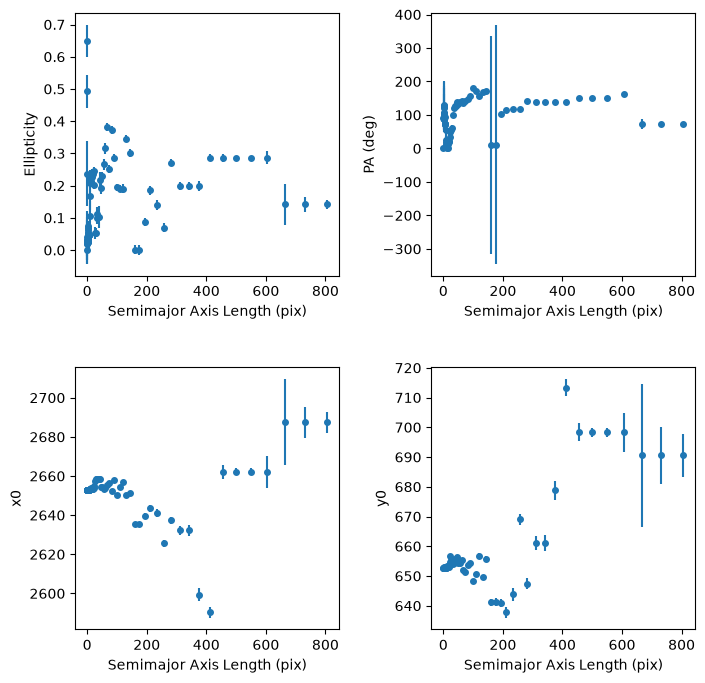

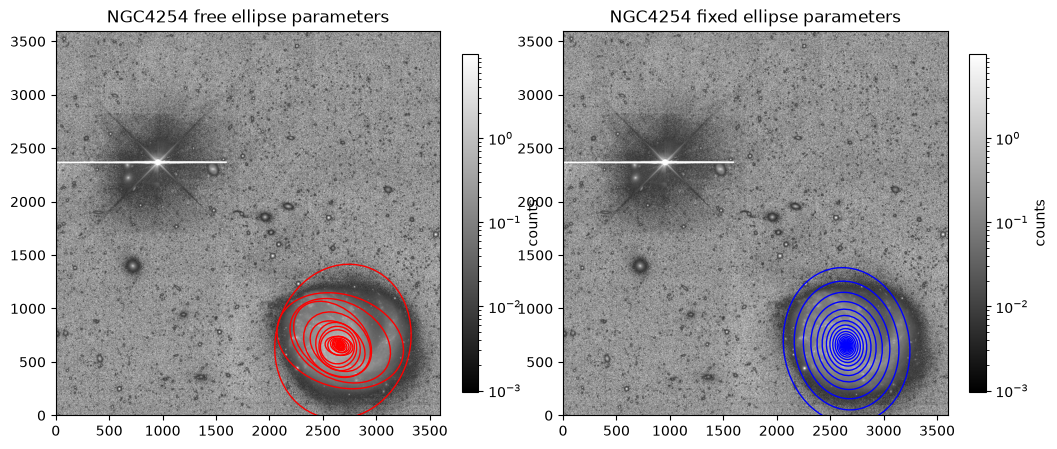

In [47]:
#this puts the output into a table containing every ellipse.   
#You can comment this first line out if you don't want it always to print out.
print(isolist[galname].eps)

#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

In [48]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC1385'
ellipse[galname] = Ellipse(data_bsub[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

[0.         0.17844297 0.17844297 0.17844297 0.11851613 0.08781232
 0.04983589 0.07536344 0.11003176 0.1409958  0.17486485 0.19948706
 0.21715375 0.23692653 0.25812832 0.27460744 0.29175381 0.31152502
 0.32132344 0.33427109 0.34762799 0.35526439 0.32505377 0.21744841
 0.06548242 0.08772463 0.13953683 0.21023733 0.28437371 0.33657507
 0.38346259 0.42380138 0.45528425 0.48196693 0.50077722 0.52055259
 0.53852748 0.55368222 0.57024211 0.58481306 0.57647352 0.54513935
 0.57228434 0.58128221 0.58690302 0.61465984 0.62453745 0.6307914
 0.63330022 0.59340091 0.51130255 0.47883307 0.14547758 0.14547758
 0.12171907 0.14374558 0.16286242 0.25788906 0.28648073 0.25370811
 0.28350212 0.25330568 0.25045629 0.34313635 0.40343774 0.4337409
 0.41990118 0.39536006 0.36994493 0.33888123 0.37439614 0.39536006
 0.39536006 0.39536006 0.39536006 0.39536006 0.39536006]
v1 =  0.00, v2 = 10.00


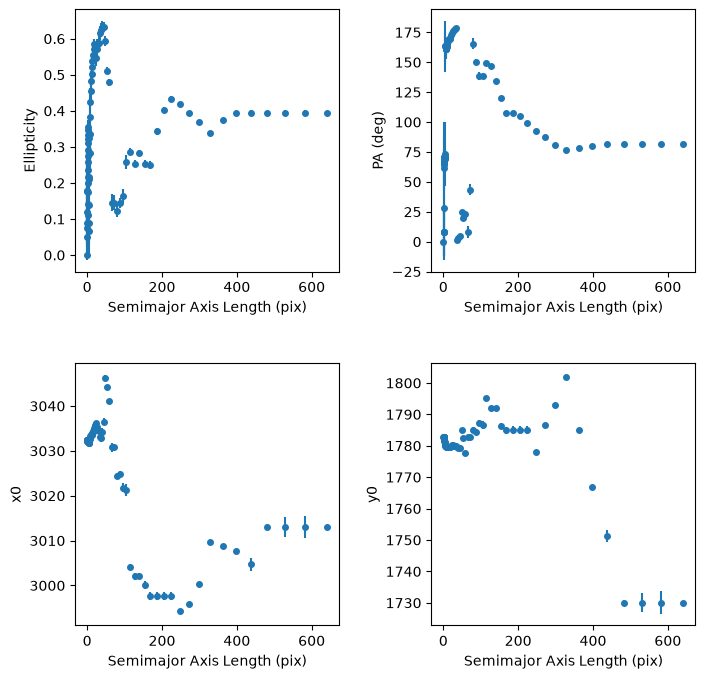

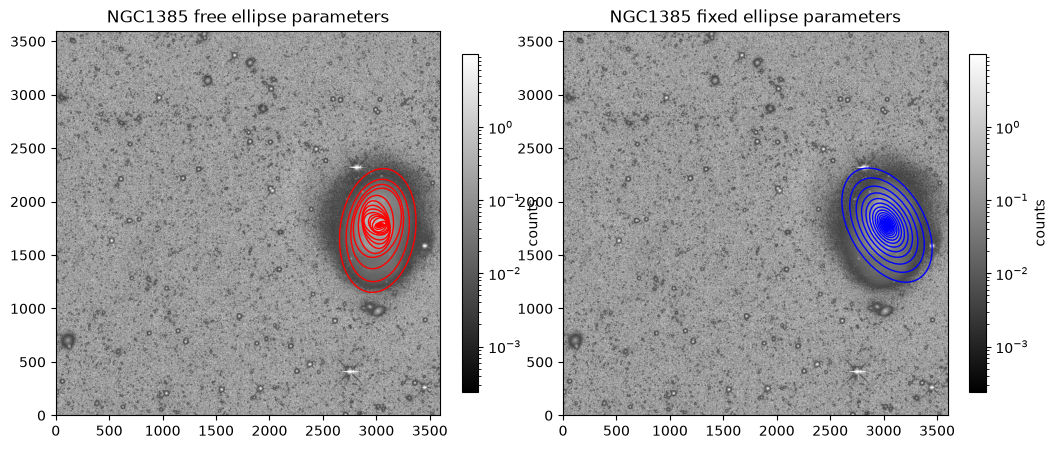

In [49]:
#this puts the output into a table containing every ellipse.   
#You can comment this first line out if you don't want it always to print out.
print(isolist[galname].eps)

#make a set of plots that show some attributes of every ellipse.
plotellipse(isolist[galname])
#save the shape values of the average ellipse.  We will need this later for aperture photometry
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data_bsub[galname],isolist[galname])

In [50]:
from photutils.aperture import ApertureStats
from photutils.aperture import EllipticalAnnulus, EllipticalAperture

In [51]:
#initialize dictionary for half-light radii
rhalfasec = {}

the half-light radius = 50.000 [asec]
surface brightness within 3 arcsec from center is 18.16468566908469
the surface brightness at the effective radius is 20.67534175844979
20.67534175844979 18.16468566908469
flux_SB(rhalf) / flux_SB(rcent) = 0.099
Central Surface Brightnes is  18.8644078543631


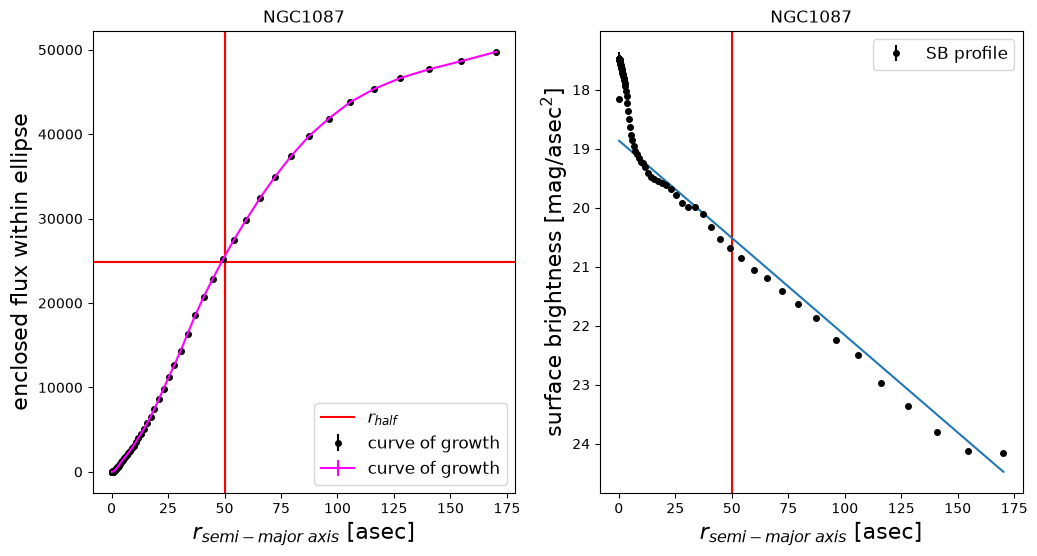

In [62]:
galname = 'NGC1087'
rhalfasec[galname] = 50.0
#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data_bsub[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data_bsub[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2
        #determine the average surface brightness in mag/asec^2.
        sb = -2.5*np.log10((aperstats_ann.sum/(np.pi*(b_out*a_out - b_in*a_in)*pixarea))) + magzp
        sbcent = np.append(sbcent, sb)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = stdflux / np.sqrt(numpix)
        avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
        sb_err = (1.086 )* (avflux_err / avflux)
        sbcent_err = np.append(sbcent_err, sb_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent,  yerr=sbcent_err,
             fmt='o', markersize=4, color='black', label='SB profile')
ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you should do this using the plot you make, not using the image itself.



ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
sb_wi_3 =(rcent <=3) # sets boolean array for within 3 asec 
print('surface brightness within 3 arcsec from center is', sbcent[sb_wi_3][0]) #prints the first value that is true 

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here


#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]
#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))
print('the surface brightness at the effective radius is', sbcent[rhalfasecind]) #print the value of surface brightness at the effective radius looking at figure value matches



#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
#use f1/f2 = 10**(-0.4*(m1-m2))

m1 = sbcent[rhalfasecind] #surface brightness as half light radius
m2 = sbcent[0] #first value of sbcent correlates to center of galaxy
print(m1 , m2) #checks values and make sure they match whats on the figure
flux_rat = 10**(-0.4*(m1-m2))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')

#calculate exponential scale length
#use I(R)= I(Re)exp[-b_n(R/Re)^1/n -1]
#need to convert sbcent into linear flux like units
#convert to nanomaggies? f_maggy = 10^-0.4*(m-22.5)
f_maggy = np.array([]) #initialize array to store flux like units
mag_flux = 10**(-0.4*(sbcent-22.5)) # convert mag/asec^2 values into nanomaggies
f_maggy= np.append(f_maggy, mag_flux) # append them to array
n=1 #for spiral galaxies
b_n = 1.999*n-0.327 #formula for b
I_R = np.array([]) #initialize array for I(R) function
Re = f_maggy[rhalfasecind] # I(Re) value calculated by hand to double check
I = Re*np.exp(-b_n*((rcent/55)**(1/n) -1))
I_R = np.append(I_R , I)
#print((I_R))
Ser_profile = 22.5-2.5*np.log10(I_R)

ax[1].plot(rcent,Ser_profile)
print('Central Surface Brightnes is ', Ser_profile[0])

the half-light radius = 87.000 [asec]
surface brightness within 3 arcsec from center is 16.34094707593762
the surface brightness at the effective radius is 21.10709354671736
21.10709354671736 16.34094707593762
flux_SB(rhalf) / flux_SB(rcent) = 0.012
Central Surface Brightnes is  19.29646103555902


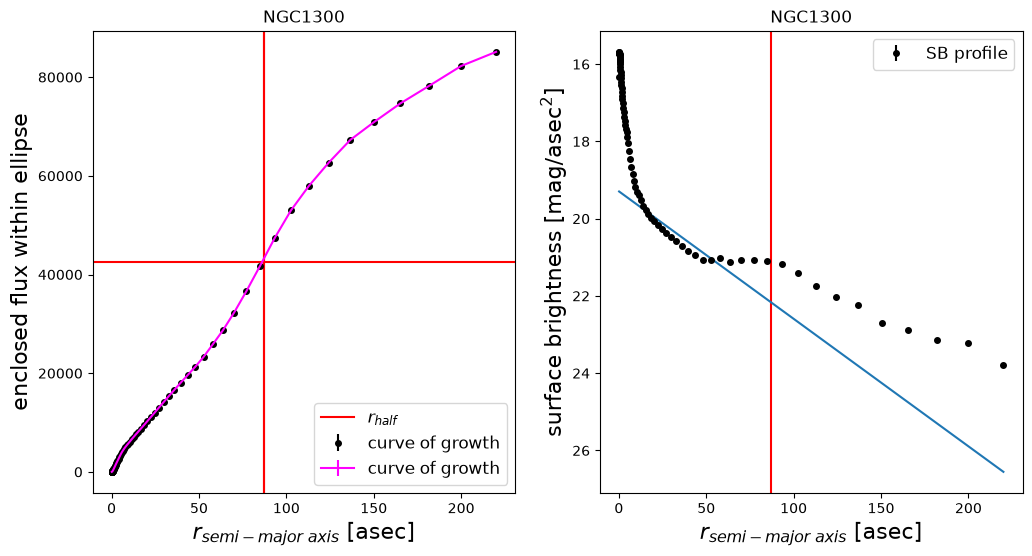

In [65]:
galname = 'NGC1300'
rhalfasec[galname] = 87.0
#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data_bsub[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data_bsub[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2
        #determine the average surface brightness in mag/asec^2.
        sb = -2.5*np.log10((aperstats_ann.sum/(np.pi*(b_out*a_out - b_in*a_in)*pixarea))) + magzp
        sbcent = np.append(sbcent, sb)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = stdflux / np.sqrt(numpix)
        avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
        sb_err = (1.086 )* (avflux_err / avflux)
        sbcent_err = np.append(sbcent_err, sb_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent,  yerr=sbcent_err,
             fmt='o', markersize=4, color='black', label='SB profile')
ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you should do this using the plot you make, not using the image itself.



ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
sb_wi_3 =(rcent <=3) # sets boolean array for within 3 asec 
print('surface brightness within 3 arcsec from center is', sbcent[sb_wi_3][0]) #prints the first value that is true 

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here


#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]
#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))
print('the surface brightness at the effective radius is', sbcent[rhalfasecind]) #print the value of surface brightness at the effective radius looking at figure value matches



#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
#use f1/f2 = 10**(-0.4*(m1-m2))

m1 = sbcent[rhalfasecind] #surface brightness as half light radius
m2 = sbcent[0] #first value of sbcent correlates to center of galaxy
print(m1 , m2) #checks values and make sure they match whats on the figure
flux_rat = 10**(-0.4*(m1-m2))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')

#calculate exponential scale length
#use I(R)= I(Re)exp[-b_n(R/Re)^1/n -1]
#need to convert sbcent into linear flux like units 
#convert to nanomaggies? f_maggy = 10^-0.4*(m-22.5)
f_maggy = np.array([]) #initialize array to store flux like units
mag_flux = 10**(-0.4*(sbcent-22.5)) # convert mag/asec^2 values into nanomaggies
f_maggy= np.append(f_maggy, mag_flux) # append them to array
n=1 #for spiral galaxies
b_n = 1.999*n-0.327 #formula for b
I_R = np.array([]) #initialize array for I(R) function
Re = f_maggy[rhalfasecind] # I(Re) value calculated by hand to double check
I = Re*np.exp(-b_n*((rcent/55)**(1/n) -1))
I_R = np.append(I_R , I)
#print((I_R))
Ser_profile = 22.5-2.5*np.log10(I_R)

ax[1].plot(rcent,Ser_profile)
print('Central Surface Brightnes is ', Ser_profile[0])

the half-light radius = 68.000 [asec]
surface brightness within 3 arcsec from center is 16.867682041118293
the surface brightness at the effective radius is 20.315631964506476
20.315631964506476 16.867682041118293
flux_SB(rhalf) / flux_SB(rcent) = 0.042
Central Surface Brightnes is  18.504805793477747


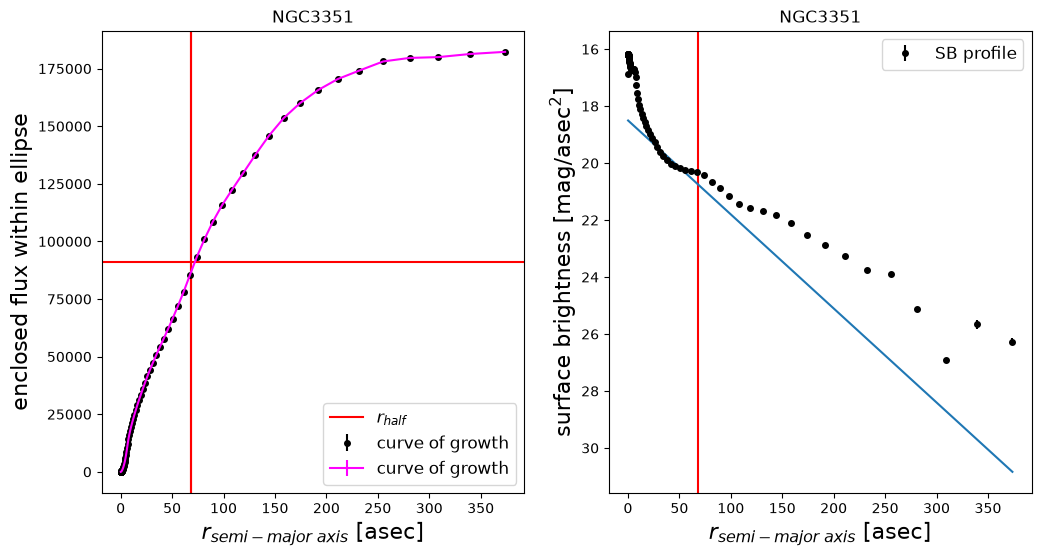

In [66]:
galname = 'NGC3351'
rhalfasec[galname] = 68.0
#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data_bsub[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data_bsub[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2
        #determine the average surface brightness in mag/asec^2.
        sb = -2.5*np.log10((aperstats_ann.sum/(np.pi*(b_out*a_out - b_in*a_in)*pixarea))) + magzp
        sbcent = np.append(sbcent, sb)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = stdflux / np.sqrt(numpix)
        avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
        sb_err = (1.086 )* (avflux_err / avflux)
        sbcent_err = np.append(sbcent_err, sb_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent,  yerr=sbcent_err,
             fmt='o', markersize=4, color='black', label='SB profile')
ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you should do this using the plot you make, not using the image itself.



ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
sb_wi_3 =(rcent <=3) # sets boolean array for within 3 asec 
print('surface brightness within 3 arcsec from center is', sbcent[sb_wi_3][0]) #prints the first value that is true 

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here


#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]
#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))
print('the surface brightness at the effective radius is', sbcent[rhalfasecind]) #print the value of surface brightness at the effective radius looking at figure value matches



#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
#use f1/f2 = 10**(-0.4*(m1-m2))

m1 = sbcent[rhalfasecind] #surface brightness as half light radius
m2 = sbcent[0] #first value of sbcent correlates to center of galaxy
print(m1 , m2) #checks values and make sure they match whats on the figure
flux_rat = 10**(-0.4*(m1-m2))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')

#calculate exponential scale length
#use I(R)= I(Re)exp[-b_n(R/Re)^1/n -1]
#need to convert sbcent into linear flux like units 
#convert to nanomaggies? f_maggy = 10^-0.4*(m-22.5)
f_maggy = np.array([]) #initialize array to store flux like units
mag_flux = 10**(-0.4*(sbcent-22.5)) # convert mag/asec^2 values into nanomaggies
f_maggy= np.append(f_maggy, mag_flux) # append them to array
n=1 #for spiral galaxies
b_n = 1.999*n-0.327 #formula for b
I_R = np.array([]) #initialize array for I(R) function
Re = f_maggy[rhalfasecind] # I(Re) value calculated by hand to double check
I = Re*np.exp(-b_n*((rcent/55)**(1/n) -1))
I_R = np.append(I_R , I)
#print((I_R))
Ser_profile = 22.5-2.5*np.log10(I_R)

ax[1].plot(rcent,Ser_profile)
print('Central Surface Brightnes is ', Ser_profile[0])

the half-light radius = 59.000 [asec]
surface brightness within 3 arcsec from center is 16.899284773719376
the surface brightness at the effective radius is 20.24242240701654
20.24242240701654 16.899284773719376
flux_SB(rhalf) / flux_SB(rcent) = 0.046
Central Surface Brightnes is  18.43159623598781


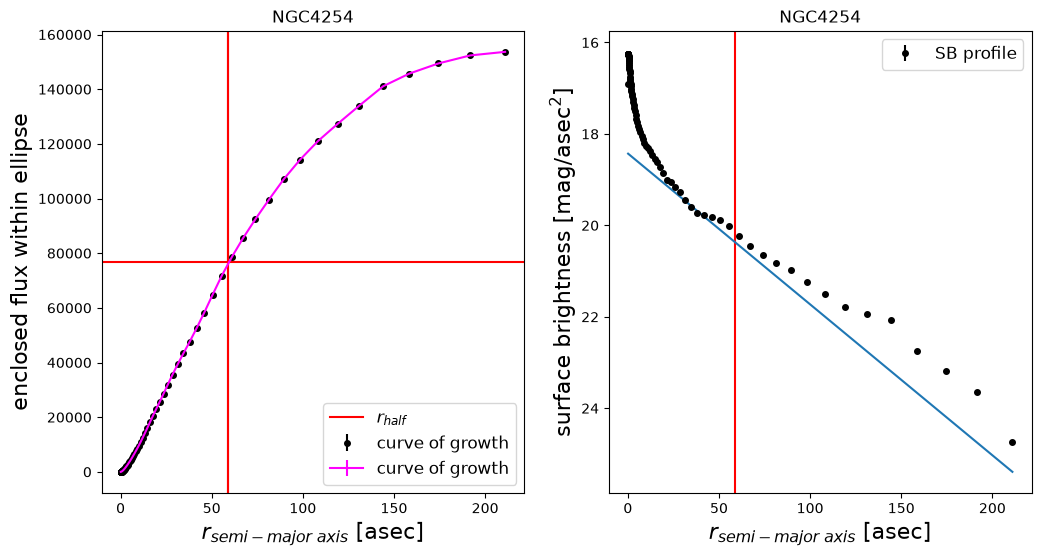

In [67]:
galname = 'NGC4254'
rhalfasec[galname] = 59.0
#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data_bsub[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data_bsub[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2
        #determine the average surface brightness in mag/asec^2.
        sb = -2.5*np.log10((aperstats_ann.sum/(np.pi*(b_out*a_out - b_in*a_in)*pixarea))) + magzp
        sbcent = np.append(sbcent, sb)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = stdflux / np.sqrt(numpix)
        avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
        sb_err = (1.086 )* (avflux_err / avflux)
        sbcent_err = np.append(sbcent_err, sb_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent,  yerr=sbcent_err,
             fmt='o', markersize=4, color='black', label='SB profile')
ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you should do this using the plot you make, not using the image itself.



ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
sb_wi_3 =(rcent <=3) # sets boolean array for within 3 asec 
print('surface brightness within 3 arcsec from center is', sbcent[sb_wi_3][0]) #prints the first value that is true 

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here


#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]
#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))
print('the surface brightness at the effective radius is', sbcent[rhalfasecind]) #print the value of surface brightness at the effective radius looking at figure value matches



#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
#use f1/f2 = 10**(-0.4*(m1-m2))

m1 = sbcent[rhalfasecind] #surface brightness as half light radius
m2 = sbcent[0] #first value of sbcent correlates to center of galaxy
print(m1 , m2) #checks values and make sure they match whats on the figure
flux_rat = 10**(-0.4*(m1-m2))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')


#calculate exponential scale length
#use I(R)= I(Re)exp[-b_n(R/Re)^1/n -1]
#need to convert sbcent into linear flux like units 
#convert to nanomaggies? f_maggy = 10^-0.4*(m-22.5)
f_maggy = np.array([]) #initialize array to store flux like units
mag_flux = 10**(-0.4*(sbcent-22.5)) # convert mag/asec^2 values into nanomaggies
f_maggy= np.append(f_maggy, mag_flux) # append them to array
n=1 #for spiral galaxies
b_n = 1.999*n-0.327 #formula for b
I_R = np.array([]) #initialize array for I(R) function
Re = f_maggy[rhalfasecind] # I(Re) value calculated by hand to double check
I = Re*np.exp(-b_n*((rcent/55)**(1/n) -1))
I_R = np.append(I_R , I)
#print((I_R))
Ser_profile = 22.5-2.5*np.log10(I_R)

ax[1].plot(rcent,Ser_profile)
print('Central Surface Brightnes is ', Ser_profile[0])

the half-light radius = 55.000 [asec]
surface brightness within 3 arcsec from center is 17.786035740023046
the surface brightness at the effective radius is 20.86399946761838
20.86399946761838 17.786035740023046
flux_SB(rhalf) / flux_SB(rcent) = 0.059
Central Surface Brightnes is  19.053006264860944


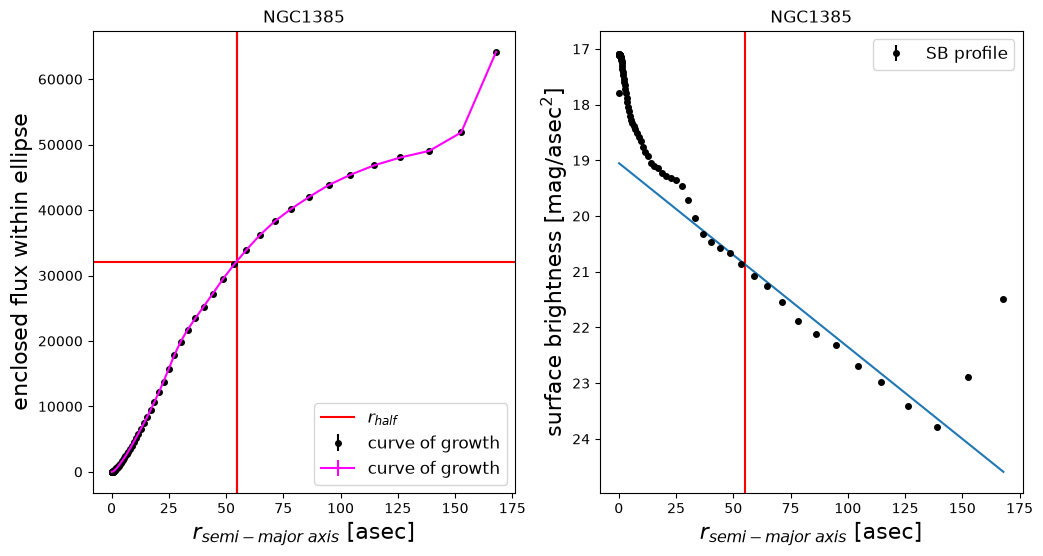

In [68]:
galname = 'NGC1385'
rhalfasec[galname] = 55.0


#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])

for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data_bsub[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data_bsub[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        
        
        #the area of a pixel
        pixarea = pixscale**2
        #determine the average surface brightness in mag/asec^2.
        sb = -2.5*np.log10((aperstats_ann.sum/(np.pi*(b_out*a_out - b_in*a_in)*pixarea))) + magzp
        sbcent = np.append(sbcent, sb)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = stdflux / np.sqrt(numpix)
        avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
        sb_err = (1.086 )* (avflux_err / avflux)
        sbcent_err = np.append(sbcent_err, sb_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent,  yerr=sbcent_err,
             fmt='o', markersize=4, color='black', label='SB profile')
ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)
#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you should do this using the plot you make, not using the image itself.



ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
#ax[1].plot(rcent, I_R)
#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
sb_wi_3 =(rcent <=3) # sets boolean array for within 3 asec 
print('surface brightness within 3 arcsec from center is', sbcent[sb_wi_3][0]) #prints the first value that is true 

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here


#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]
#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))
print('the surface brightness at the effective radius is', sbcent[rhalfasecind]) #print the value of surface brightness at the effective radius looking at figure value matches



#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
#use f1/f2 = 10**(-0.4*(m1-m2))

m1 = sbcent[rhalfasecind] #surface brightness as half light radius
m2 = sbcent[0] #first value of sbcent correlates to center of galaxy
print(m1 , m2) #checks values and make sure they match whats on the figure
flux_rat = 10**(-0.4*(m1-m2))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')

#calculate exponential scale length
#use I(R)= I(Re)exp[-b_n(R/Re)^1/n -1]
#need to convert sbcent into linear flux like units 
#convert to nanomaggies? f_maggy = 10^-0.4*(m-22.5)
f_maggy = np.array([]) #initialize array to store flux like units
mag_flux = 10**(-0.4*(sbcent-22.5)) # convert mag/asec^2 values into nanomaggies
f_maggy= np.append(f_maggy, mag_flux) # append them to array
n=1 #for spiral galaxies
b_n = 1.999*n-0.327 #formula for b
I_R = np.array([]) #initialize array for I(R) function
Re = f_maggy[rhalfasecind] # I(Re) value calculated by hand to double check
I = Re*np.exp(-b_n*((rcent/55)**(1/n) -1))
I_R = np.append(I_R , I)
#print((I_R))
Ser_profile = 22.5-2.5*np.log10(I_R)

ax[1].plot(rcent,Ser_profile)
print('Central Surface Brightnes is ', Ser_profile[0])